In [1]:
# Permite importar src/ desde la carpeta notebooks/
import sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import DIR_DATA_RAW

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

In [2]:
from src.config import DIR_DATA_PROC
from src.variables import construir_variables, verificar_sin_futuro, FEATURES
from src.etiquetas import etiquetar

tel_v = pd.read_parquet(DIR_DATA_PROC / "telemetria_viajes.parquet")
vf = pd.read_parquet(DIR_DATA_PROC / "ventanas_calas.parquet")

# 1. Variables y prueba de fuga con datos reales
tel_f = construir_variables(tel_v)
print("Sin datos del futuro:", verificar_sin_futuro(tel_v.sample(5000, random_state=1).sort_values(["ep", "fecha"]), n=50))
display(tel_f[FEATURES].isna().mean().round(3).sort_values(ascending=False).head(8).to_frame("% vacíos"))

# 2. Etiquetas con transiciones
tel_e = etiquetar(tel_f, vf)
display(tel_e["Etiqueta"].value_counts().to_frame("registros"))
display(tel_e.groupby("Etiqueta")[["Velocidad", "Velocidad_delta", "rpm", "rpm_delta",
                                   "gal_h", "gal_h_delta", "GiroAcum3"]].median().round(1))

tel_e.to_parquet(DIR_DATA_PROC / "telemetria_etiquetada.parquet", index=False)

Sin datos del futuro: True


,% vacíos
CambioRumboGPS,0.25
rpm_lag2,0.04
gal_h_lag2,0.04
Velocidad_lag2,0.04
gal_h_lag1,0.02
rpm_lag1,0.02
Velocidad_delta,0.02
Velocidad_std4,0.02


,registros
Etiqueta,
sin_viaje,85518
busqueda,37817
retorno,26765
ida,20866
cala,13453
viaje_sin_cala,8792
entrada_cala,2276
salida_cala,2225


,Velocidad,Velocidad_delta,rpm,rpm_delta,gal_h,gal_h_delta,GiroAcum3
Etiqueta,,,,,,,
busqueda,10.00,0.00,916.00,0.00,52.10,0.00,24.10
cala,0.60,-0.10,673.00,-1.00,12.70,-1.60,27.10
entrada_cala,6.80,-0.80,859.00,-11.00,33.90,-0.50,99.40
ida,11.60,0.00,"1,205.00",0.00,57.90,0.00,7.70
retorno,10.80,0.00,"1,194.00",0.00,58.40,0.00,6.40
salida_cala,8.90,7.90,920.00,282.00,43.70,28.00,29.40
sin_viaje,9.70,0.00,902.00,0.00,48.10,0.00,3.50
viaje_sin_cala,10.80,0.00,"1,144.00",0.00,55.20,0.00,12.70


In [3]:
e = tel_e.copy()
e["sig_etq"] = e.groupby("Tramo")["Etiqueta"].shift(-1)
e["pos_entrada"] = np.where(e["Etiqueta"] != "entrada_cala", None,
                     np.where(e["sig_etq"] == "cala", "justo antes de la cala", "2 registros antes"))
cols6a = ["Velocidad", "Velocidad_lag1", "Velocidad_delta",
          "rpm", "rpm_lag1", "rpm_delta", "gal_h", "gal_h_delta", "GiroAcum3"]
display(e[e["Etiqueta"] == "entrada_cala"].groupby("pos_entrada")[cols6a].median().round(1))

,Velocidad,Velocidad_lag1,Velocidad_delta,rpm,rpm_lag1,rpm_delta,gal_h,gal_h_delta,GiroAcum3
pos_entrada,,,,,,,,,
2 registros antes,6.40,9.50,-0.50,599.00,883.50,-27.50,44.80,-2.90,62.90
justo antes de la cala,6.80,9.20,-0.80,863.00,992.00,-11.00,33.80,-0.50,100.30


Clase
sin etiqueta                  3817
positiva (cala registrada)    2395
negativa (puerto)             2172
Name: count, dtype: int64

Clase,negativa (puerto),positiva (cala registrada),sin etiqueta
duracion_min,75.00,75.70,75.00
galh_mediana,3.50,12.50,5.40
rpm_mediana,450.00,672.00,481.00
rpm_std,1.20,36.60,2.80
vel_antes,3.90,7.40,6.60
vel_despues,4.00,8.30,7.10
giro_antes,3.80,68.80,34.40
giro_despues,0.00,77.50,42.50
deriva_km,0.00,0.60,0.60
hora_inicio,14.00,9.00,11.00


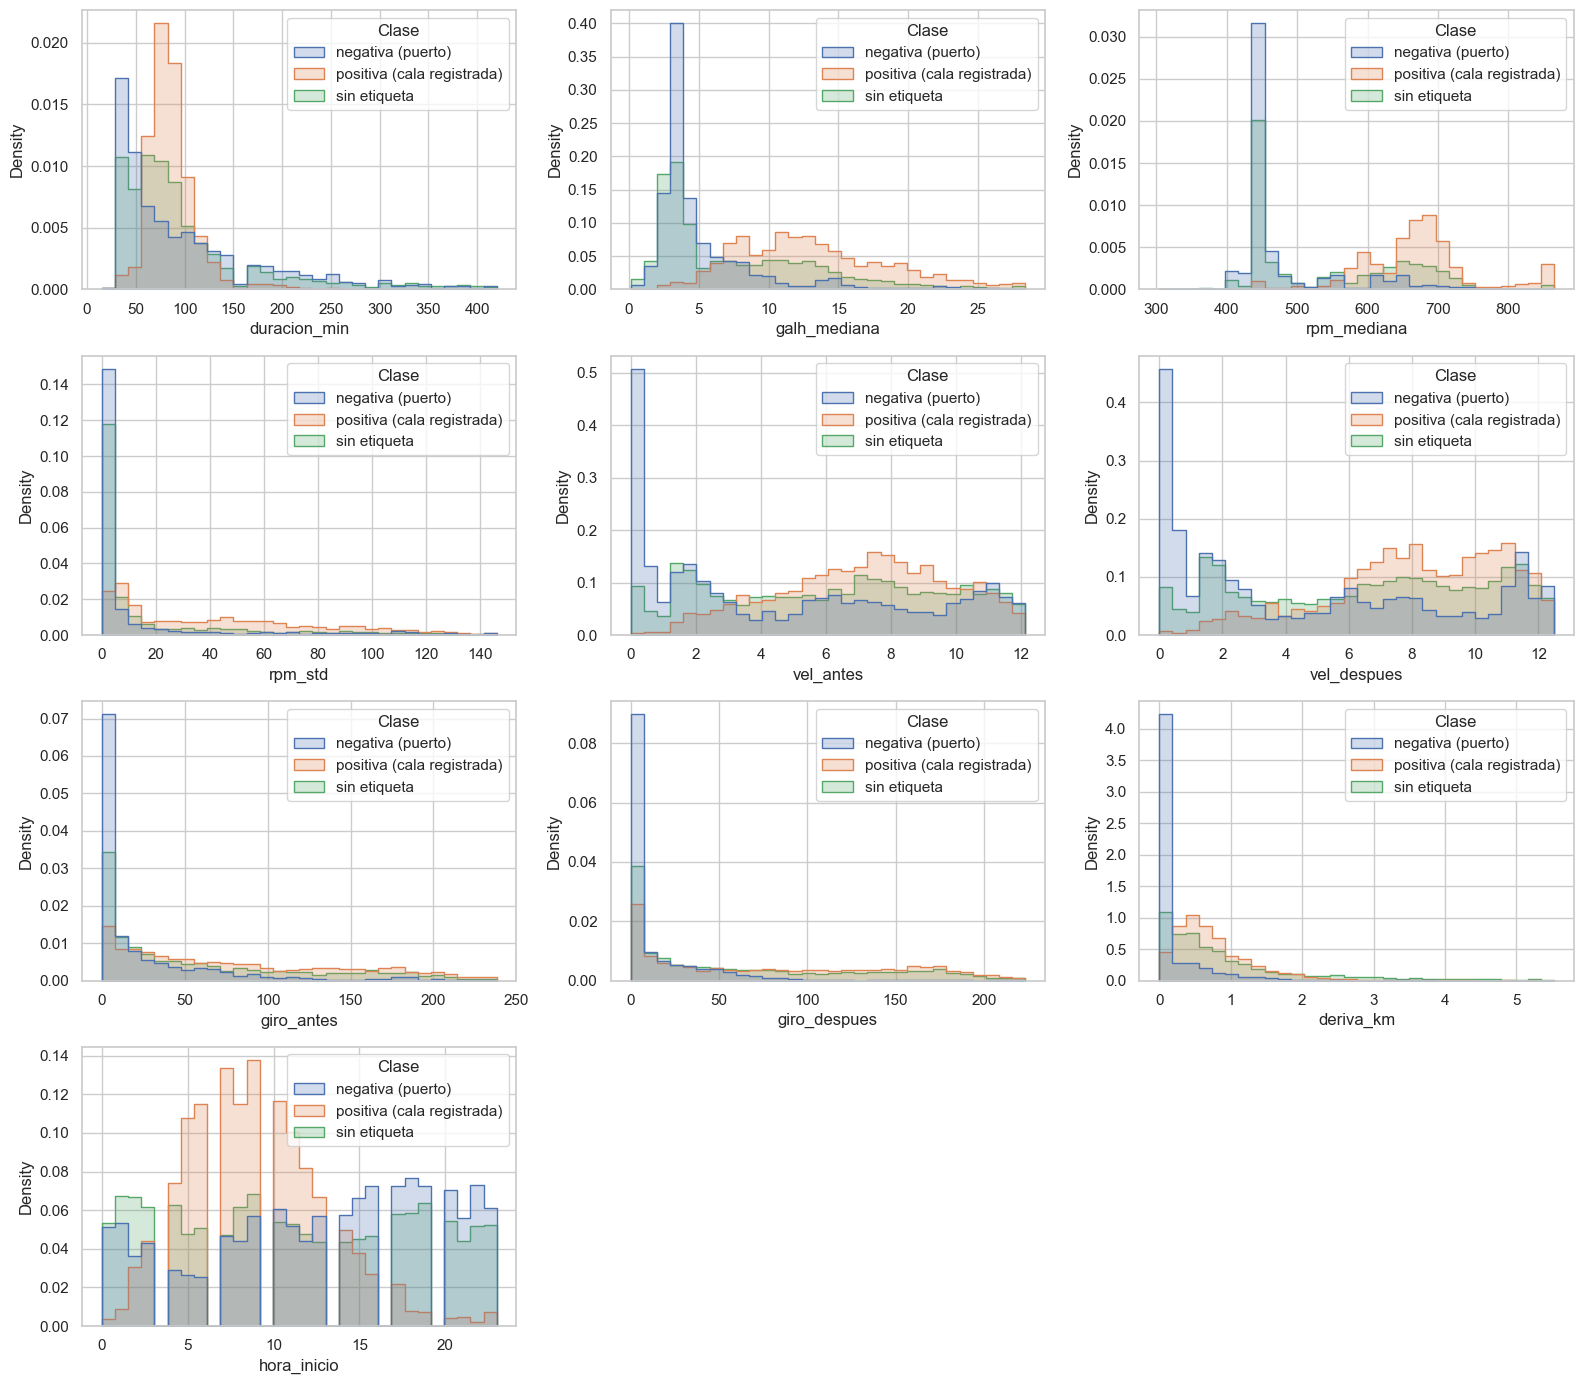

In [4]:
from src.paradas import detectar_paradas, marcar_calas_registradas
viajes = pd.read_parquet(DIR_DATA_PROC / "viajes.parquet")

par = detectar_paradas(tel_f)
par = marcar_calas_registradas(par, vf, viajes)
par["Clase"] = np.select(
    [par["Tipo"] == "cala_registrada", par["dist_puerto_km"] <= 5],
    ["positiva (cala registrada)", "negativa (puerto)"],
    "sin etiqueta")

display(par["Clase"].value_counts())
cols = ["duracion_min", "galh_mediana", "rpm_mediana", "rpm_std", "vel_antes", "vel_despues",
        "giro_antes", "giro_despues", "deriva_km", "hora_inicio"]
display(par.groupby("Clase")[cols].median().T.round(1))

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
for ax, col in zip(axes.flat, cols):
    lim = par[col].quantile(0.98)
    sns.histplot(data=par[par[col] <= lim], x=col, hue="Clase", stat="density",
                 common_norm=False, bins=30, element="step", ax=ax)
for ax in axes.flat[len(cols):]:
    ax.axis("off")
plt.tight_layout()

c = P(una cala se registre) = 0.56
Calas registradas reconocidas (P ≥ 0.5): 81.6%


Prediccion,cala,no cala,posible cala,All
Clase,,,,
negativa (puerto),0,2172,0,2172
positiva (cala registrada),1955,139,301,2395
sin etiqueta,1100,2466,251,3817
All,3055,4777,552,8384


Calas nuevas por viaje: {'count': 0.0, 'mean': nan, 'std': nan, 'min': nan, '25%': nan, '50%': nan, '75%': nan, 'max': nan}
Calas probables fuera de viaje (mar sin faena): 0


,importancia
galh_std,0.06
rpm_mediana,0.06
galh_mediana,0.03
vel_antes,0.03
duracion_min,0.02
rpm_std,0.02
vel_media,0.02
vel_despues,0.02
hora_sin,0.01
hora_cos,0.01


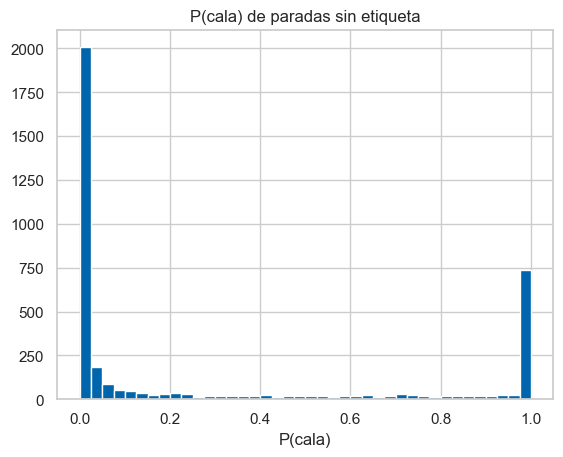

In [5]:
from src.modelo_paradas import entrenar_pu, clasificar, VARIABLES
from sklearn.inspection import permutation_importance

p, c, modelo = entrenar_pu(par)
p["Prediccion"] = clasificar(p["P_cala"])
print(f"c = P(una cala se registre) = {c:.2f}")

# 1. ¿Reconoce las calas registradas que no vio?
pos = p[p["s"] == 1]
print(f"Calas registradas reconocidas (P ≥ 0.5): {(pos['P_cala'] >= 0.5).mean():.1%}")

# 2. Resultado por clase de parada
display(pd.crosstab(p["Clase"], p["Prediccion"], margins=True))

# 3. Distribución de la probabilidad en las sin etiqueta: ¿se separa en dos grupos?
p.loc[p["Clase"] == "sin etiqueta", "P_cala"].hist(bins=40, color="#0065AC")
plt.title("P(cala) de paradas sin etiqueta"); plt.xlabel("P(cala)")

# 4. Coherencia por viaje: calas nuevas por viaje (no debería dispararse)
nuevas = p[(p["s"] == 0) & (p["Prediccion"] == "cala probable") & p["IdViaje"].notna()]
print("Calas nuevas por viaje:", nuevas.groupby("IdViaje").size().describe().round(1).to_dict())
print("Calas probables fuera de viaje (mar sin faena):",
      ((p["s"] == 0) & (p["Prediccion"] == "cala probable") & p["IdViaje"].isna()).sum())

# 5. ¿En qué se fija el modelo?
X = p[VARIABLES]
imp = permutation_importance(modelo, X, p["s"], n_repeats=5, random_state=0, scoring="roc_auc")
display(pd.Series(imp.importances_mean, index=VARIABLES).sort_values(ascending=False).round(3).to_frame("importancia"))

p.to_parquet(DIR_DATA_PROC / "paradas_pu.parquet", index=False)
p[p["Prediccion"] == "dudosa"].to_csv(DIR_DATA_PROC / "paradas_por_revisar.csv", index=False)

,A · PU (cota inferior),B · vs puerto (cota superior)
AUC-ROC,0.88,0.99
Gini,0.76,0.97
AP (área PR),0.64,0.98
Accuracy,0.81,0.90
Precision,0.63,0.99
Recall,0.82,0.82
F1,0.71,0.89


Puntos de corte óptimos: {'Lee-Liu (PU, recomendado)': 0.21, 'Youden (vs puerto)': 0.11, 'F1 (vs puerto)': 0.11}


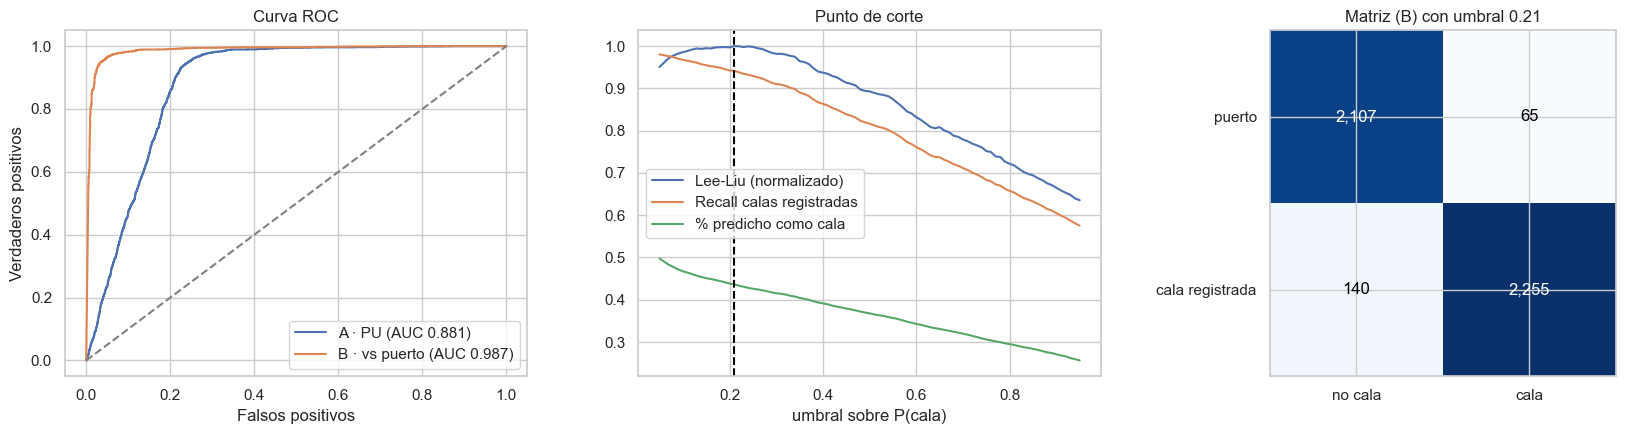

,recall_registradas,pct_predicho_cala,Lee_Liu,Youden_vs_puerto,F1_vs_puerto
umbral,,,,,
0.30,0.91,0.41,1.99,0.89,0.94
0.50,0.82,0.37,1.81,0.80,0.89
0.70,0.71,0.32,1.58,0.70,0.83
0.21,0.94,0.44,2.03,0.91,0.96


con deriva                                \
             A · PU (cota inferior) B · vs puerto (cota superior)   
AUC-ROC                        0.88                          0.99   
Gini                           0.76                          0.97   
AP (área PR)                   0.64                          0.98   
Accuracy                       0.81                          0.90   
Precision                      0.63                          0.99   
Recall                         0.82                          0.82   
F1                             0.71                          0.89   

                         sin deriva                                
             A · PU (cota inferior) B · vs puerto (cota superior)  
AUC-ROC                        0.88                          0.99  
Gini                           0.76                          0.97  
AP (área PR)                   0.64                          0.98  
Accuracy                       0.81                          0.90  
Precision                      0.63                          0.99  
Recall                         0.82                          0.82  
F1                             0.71                          0.89

Corte sin deriva: 0.21


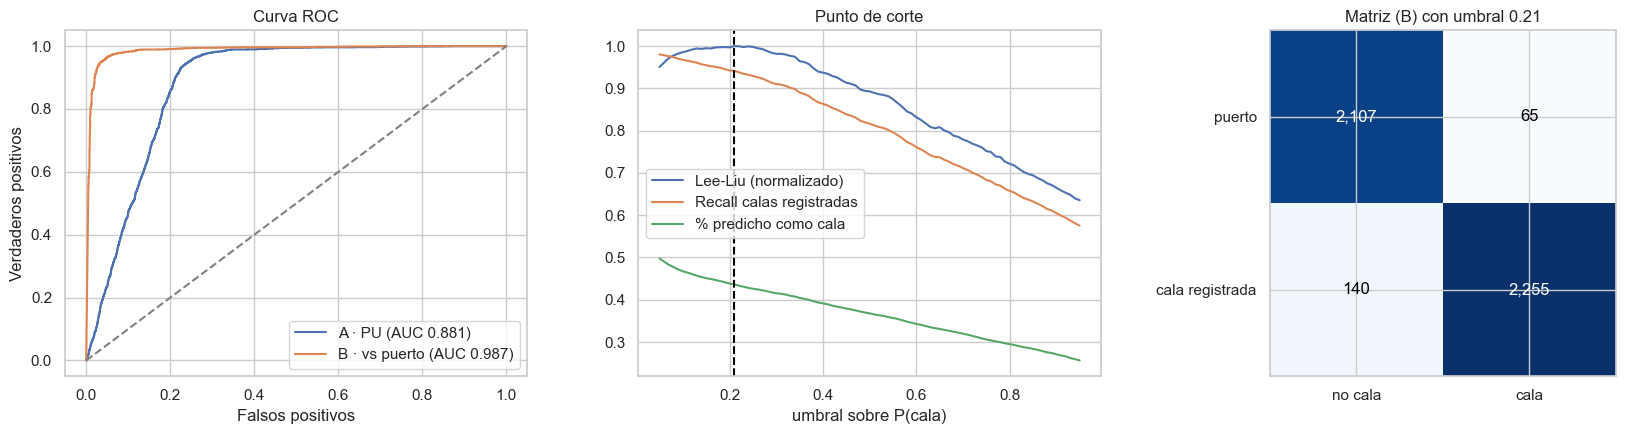

In [6]:
from src.evaluacion_pu import evaluar
from src.modelo_paradas import entrenar_pu, clasificar, VARIABLES

# 1. Indicadores y punto de corte del modelo actual
tabla, cortes, mejor = evaluar(p, c)
display(tabla)
print("Puntos de corte óptimos:", {k: float(v) for k, v in mejor.items()})
plt.show()

u = mejor["Lee-Liu (PU, recomendado)"]
display(cortes.set_index("umbral").loc[[0.3, 0.5, 0.7, u]].round(3))

# 2. Prueba sin deriva_km (¿el modelo depende de la regla del puerto?)
import src.modelo_paradas as mp
mp.VARIABLES = [v for v in VARIABLES if v != "deriva_km"]
p2, c2, modelo2 = mp.entrenar_pu(par)
tabla2, _, mejor2 = evaluar(p2, c2)
mp.VARIABLES = VARIABLES                                   # restaurar

display(pd.concat({"con deriva": tabla, "sin deriva": tabla2}, axis=1))
print("Corte sin deriva:", float(mejor2["Lee-Liu (PU, recomendado)"]))

In [7]:
import joblib, datetime
from src.config import DIR_MODELOS
from src.modelo_paradas import entrenar_pu, clasificar, VARIABLES

p, c, modelo = entrenar_pu(par)
p["Prediccion"] = clasificar(p["P_cala"])
display(pd.crosstab(p["Clase"], p["Prediccion"], margins=True))

# El modelo y TODO lo necesario para usarlo en producción, en un solo archivo
DIR_MODELOS.mkdir(exist_ok=True)
joblib.dump({
    "modelo": modelo, "c": c, "variables": VARIABLES,
    "umbral_cala": 0.5, "umbral_revision": 0.2,
    "version": "paradas_pu_v1", "entrenado": datetime.datetime.now().isoformat(timespec="minutes"),
    "metricas": {"auc_pu": 0.88, "auc_vs_puerto": 0.99, "recall_umbral_0.2": 0.95},
}, DIR_MODELOS / "paradas_pu_v1.joblib")

p.to_parquet(DIR_DATA_PROC / "paradas_pu.parquet", index=False)
p[p["Prediccion"] == "posible cala"].to_csv(DIR_DATA_PROC / "paradas_por_revisar.csv", index=False)
print("Calas nuevas (no registradas):", ((p["s"] == 0) & (p["Prediccion"] == "cala")).sum())

Prediccion,cala,no cala,posible cala,All
Clase,,,,
negativa (puerto),0,2172,0,2172
positiva (cala registrada),1955,139,301,2395
sin etiqueta,1100,2466,251,3817
All,3055,4777,552,8384


Calas nuevas (no registradas): 1100
